# Imputation using Regression on Missing Data

## Imports

In [1]:
import pandas as pd
import numpy as np
import sklearn
from sklearn.preprocessing import StandardScaler
import lazypredict
from sklearn.model_selection import *
import random
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from sklearn.linear_model import LinearRegression, LogisticRegression, RidgeCV, LassoCV
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import *
from sklearn import tree
from sklearn.decomposition import PCA
import seaborn as sns
from sklearn.pipeline import Pipeline

## Introduction of Random Deletions

In [9]:
df = pd.read_csv('data/UCI_Credit_Card.csv')

The dataset is imbalanced, with roughly 1:3.5 ratio between Default and Not Default

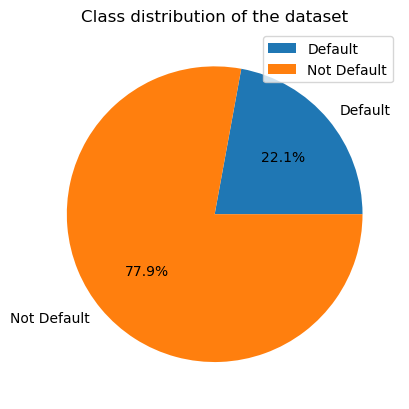

In [10]:
plt.pie(
    x = [len(df[df['default.payment.next.month'] == 1]), len(df[df['default.payment.next.month'] == 0])],
    labels=['Default', 'Not Default'],
    autopct='%1.1f%%'
    )
plt.legend()
plt.title("Class distribution of the dataset")
plt.show()

Features: ID -> PAY_AMT6

Label: default.payment.next.month

In [11]:
df.describe()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
count,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,...,30000.000000,30000.000000,30000.000000,30000.000000,3.000000e+04,30000.00000,30000.000000,30000.000000,30000.000000,30000.000000
mean,15000.500000,167484.322667,1.603733,1.853133,1.551867,35.485500,-0.016700,-0.133767,-0.166200,-0.220667,...,43262.948967,40311.400967,38871.760400,5663.580500,5.921163e+03,5225.68150,4826.076867,4799.387633,5215.502567,0.221200
std,8660.398374,129747.661567,0.489129,0.790349,0.521970,9.217904,1.123802,1.197186,1.196868,1.169139,...,64332.856134,60797.155770,59554.107537,16563.280354,2.304087e+04,17606.96147,15666.159744,15278.305679,17777.465775,0.415062
min,1.000000,10000.000000,1.000000,0.000000,0.000000,21.000000,-2.000000,-2.000000,-2.000000,-2.000000,...,-170000.000000,-81334.000000,-339603.000000,0.000000,0.000000e+00,0.00000,0.000000,0.000000,0.000000,0.000000
25%,7500.750000,50000.000000,1.000000,1.000000,1.000000,28.000000,-1.000000,-1.000000,-1.000000,-1.000000,...,2326.750000,1763.000000,1256.000000,1000.000000,8.330000e+02,390.00000,296.000000,252.500000,117.750000,0.000000
50%,15000.500000,140000.000000,2.000000,2.000000,2.000000,34.000000,0.000000,0.000000,0.000000,0.000000,...,19052.000000,18104.500000,17071.000000,2100.000000,2.009000e+03,1800.00000,1500.000000,1500.000000,1500.000000,0.000000
75%,22500.250000,240000.000000,2.000000,2.000000,2.000000,41.000000,0.000000,0.000000,0.000000,0.000000,...,54506.000000,50190.500000,49198.250000,5006.000000,5.000000e+03,4505.00000,4013.250000,4031.500000,4000.000000,0.000000
max,30000.000000,1000000.000000,2.000000,6.000000,3.000000,79.000000,8.000000,8.000000,8.000000,8.000000,...,891586.000000,927171.000000,961664.000000,873552.000000,1.684259e+06,896040.00000,621000.000000,426529.000000,528666.000000,1.000000


Randomly select the columns to replaced with missing values

In [12]:
missing_columns = ['AGE'] + [f'BILL_AMT{i}' for i in np.random.choice(a = list(range(1, 7)), size=2)]
missing_columns

['AGE', 'BILL_AMT3', 'BILL_AMT1']

Split into training and testing

In [13]:
train_df1, test_df1 = train_test_split(df, test_size=0.2, stratify=df['default.payment.next.month'])

Introduce MAR (Missing at random) values for 5% of each split

In [14]:
ds = {"train": train_df1, "test": test_df1}
for d in ds:
    mar_df = ds[d].copy(deep=True)
    actual_vals = dict()
    for col in missing_columns:
        mar_rows = ds[d][col].sample(frac = 0.05, random_state=1)
        mar_df.loc[mar_rows.index, col] = np.nan
        actual_vals[col] = ds[d][col].values
    actual_vals = pd.DataFrame(actual_vals)
    mar_df.to_csv(f'data/mar_credit_{d}.csv', index=False)
    actual_vals.to_csv(f'data/actual_vals_{d}.csv', index=False)

## Part A

Load all the four datasets

In [15]:
train_df, test_df = pd.read_csv("data/mar_credit_train.csv"), pd.read_csv("data/mar_credit_test.csv")
train_actual, test_actual = pd.read_csv("data/actual_vals_train.csv"), pd.read_csv("data/actual_vals_test.csv")
ds1 = {"train": train_df, "test": test_df}
actual = {"train": train_actual, "test": test_actual}

In [16]:
labels = pd.concat([train_df['default.payment.next.month'], test_df['default.payment.next.month']])

In [17]:
missing_columns = train_actual.columns
missing_columns

Index(['AGE', 'BILL_AMT3', 'BILL_AMT1'], dtype='object')

In [18]:
target_missing_column = random.choice(missing_columns)
target_missing_column
# target_missing_column = 'AGE'

'BILL_AMT1'

In [19]:
target_classifier_feature = 'default.payment.next.month'

Categorical features:
1. ID
2. SEX
3. EDUCATION
4. MARRIAGE
5. PAY_{[0...6]}

Ordinal Categorical features:
1. AGE

Numeric features:
1. LIMIT_BAL
2. PAY_AMT{[0...6]}
3. BILL_AMT{[0...6]}

Standardizing the numeric features:

In [20]:
categorical_columns = ['ID', 'SEX', 'EDUCATION', 'MARRIAGE'] + [f'PAY_{i}' for i in range(0, 7) if i!=1]

In [21]:
numeric_columns = [
    col
    for col in ds1['train'].columns
    if col not in categorical_columns and col not in missing_columns and col != target_classifier_feature
]

In [22]:
features = categorical_columns + numeric_columns

In [23]:
for d in ds1:
    ds1[d][numeric_columns] = StandardScaler().fit_transform(ds1[d][numeric_columns])

Now, the issue is we have missing values in the columns of AGE and 2 columns of BILL_AMT (it is randomly selected while creating the dataset). We cannot use this dataset directly for the classification purpose as the missing values can hamper a classifier's performance, as they could have held key relations to other features and label necessary for making the classification. To get around this, we perform what is known as <b>Imputation</b> where we fill the missing values with some strategies.

### Imputation Method 1 : Median

We fill the missing values in a particular column with the median value of the column values. We use median over the mean as it picks the value that actually exists in the data thereby avoiding any kind of bias.

In [24]:
combined_df = pd.concat([ds1['train'], ds1['test']])
for col in missing_columns:
    combined_df = combined_df.fillna(combined_df[col].median())
combined_df.to_csv(f"data/median.csv", index=False)

### Imputation Method 2 : Linear Regression

Substituting the missing values with just the median can introduce significant bias in the features. This can negatively affect the classifier's performance. Instead, we can assume a linear relationship between the feature and rest of the features and regress over the values.

In [25]:
X_train, y_train = ds1['train'][features], actual['train'][target_missing_column]
X_test, y_test = ds1['test'][features], actual['test'][target_missing_column]

In [26]:
def linreg(model):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    return model, model.score(X_test, y_test), y_pred

In [27]:
def combine(pred, name):
    X = pd.concat([X_train, X_test])
    X[target_missing_column] = pd.concat([y_train, pd.Series(pred)])
    X[target_classifier_feature] = labels
    X.to_csv(f"data/{name}.csv", index=False)
    return X

#### Simple Linear Regression

In [28]:
lr, err, pred = linreg(LinearRegression(fit_intercept=False, copy_X=True))
print(err)
linreg_df = combine(pred, "linreg")

0.8989807944232753


#### Linear Ridge Regression

In [29]:
alphas = [0.01, 0.02, 0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.7, 0.75, 0.8, 1, 1.5, 2, 2.5, 3, 4, 5, 10]

In [30]:
model = RidgeCV(alphas=alphas, store_cv_results=True).fit(X_train, y_train)
pred = model.predict(X_test)
model.score(X_test, y_test)

0.9122666904442763

In [31]:
ridge_df = combine(pred, name = 'ridge')

#### Linear Lasso Regression

In [32]:
alphas = [0.01, 0.02, 0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.7, 0.75, 0.8, 1, 1.5, 2, 2.5, 3, 4, 5, 10]

In [33]:
model = LassoCV().fit(X_train, y_train)
pred = model.predict(X_test)
model.score(X_test, y_test)

0.8683694943272796

In [34]:
lasso_df = combine(pred, name="lasso")

### Imputation Method 3 : Non-linear Regression

Assuming a linear relationship might be too simple for the data, so we might decide to assume a more general but complex non-linear relationship between the features and then perform a non-linear regression on the same.

In [42]:
def nonlinreg(model):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    return model, model.score(X_test, y_test), y_pred

In [36]:
def combine(pred, name):
    X = pd.concat([X_train, X_test])
    X[target_missing_column] = pd.concat([y_train, pd.Series(pred)])
    X[target_classifier_feature] = labels
    X.to_csv(f"data/{name}.csv", index=False)
    return X

#### KNeighbors Regression

In [43]:
nns = [1, 2, 3, 4, 5, 7, 10, 12, 15, 20, 25, 30, 35, 40, 45, 50, 75, 100]
parameters = {'n_neighbors':nns}
knn = KNeighborsRegressor()

In [44]:
clf = GridSearchCV(knn, parameters)
clf = clf.fit(X_train, y_train)
pred = clf.predict(X_test)
clf.score(X_test, y_test)

0.24021528700209904

In [45]:
knn_df = combine(pred, name='knn')

#### Decision Tree Regression

In [46]:
model, error, pred = nonlinreg(tree.DecisionTreeRegressor())
dreg_df = combine(pred, "decisiontree")
print(error)

0.8452153673892302


### Imputation Method 4 : Deletion of missing values

In [47]:
drop_df = pd.concat([train_df.dropna(), test_df.dropna()])
drop_df.to_csv("data/drop.csv", index=False)

## Part B

In [50]:
def report_generator(y_test, y_pred, name):
    """
        Generate a comprehensive report based on various metrics
        Implemented from sklearn
    """

    y_test = y_test.to_numpy()
    x = ["Default", "Not Default"]
    actual_default, predict_default = y_test[np.where(y_test == 1)[0]], y_pred[np.where(y_test == 1)[0]]
    actual_not_default, predict_not_default = y_test[np.where(y_test == 0)[0]], y_pred[np.where(y_test == 0)[0]]

    report = {
        "Default": {
            "precision": precision_score(actual_default, predict_default),
            "recall": recall_score(actual_default, predict_default),
            "f1": f1_score(actual_default, predict_default),
            "bal_acc": balanced_accuracy_score(actual_default, predict_default),
            "accuracy": accuracy_score(actual_default, predict_default),
            "size": len(actual_default)
        },
        "Not Default": {
            "precision": precision_score(actual_not_default, predict_not_default),
            "recall": recall_score(actual_not_default, predict_not_default),
            "f1": f1_score(actual_not_default, predict_not_default),
            "bal_acc": balanced_accuracy_score(actual_not_default, predict_not_default),
            "accuracy": accuracy_score(actual_not_default, predict_not_default),
            "size": len(actual_not_default)
        },
        "precision": precision_score(y_test, y_pred),
        "recall": recall_score(y_test, y_pred),
        "pr_curve": precision_recall_curve(y_test, y_pred),
        "f1": f1_score(y_test, y_pred),
        "confusion_matrix": confusion_matrix(y_test, y_pred),
        "roc_curve": roc_curve(y_test, y_pred),
        "likelihood_ratios": class_likelihood_ratios(y_test, y_pred),
        "bal_acc": balanced_accuracy_score(y_test, y_pred),
        "mcc": matthews_corrcoef(y_test, y_pred),
        "accuracy": accuracy_score(y_test, y_pred),
        "roc_auc": roc_auc_score(y_test, y_pred),
        "avg_p": average_precision_score(y_test, y_pred)
    }
    default, not_default = report['Default'], report['Not Default']

    fig, axs = plt.subplots(3, 2, figsize= (10, 10), constrained_layout = True)
    color_palette = [
        '#0072B2',  # Cerulean Blue
        '#D55E00',  # Vermillion
    ]
    k, l = 0, 0
    for i, j in zip(default, not_default):
        if i != 'size':
            y = [default[i], not_default[j]]
            axs[k, l].bar(x, height = y, color = color_palette)
            axs[k, l].set_ylim(0, 1.1)
            axs[k, l].set_ylabel(f"{i.capitalize()} Value")
        else:
            y = [np.log(default[i]), np.log(not_default[j])]
            axs[k, l].bar(x, height = y, color = color_palette)
            axs[k, l].set_ylabel(f"Log of {i.capitalize()} Value")
        
        for q in range(len(x)):
            axs[k, l].text(q, y[q], np.round(y[q], 2), ha='center')  # Aligning text at center

        axs[k, l].set_title(f"{i.capitalize()} Comparison")
        l += 1
        if l == 2:
            k += 1
            l = 0

    fig.suptitle(f"Comparison of Metrics between Default and Not Default Classes in {name}")
    fig.align_xlabels(axs)
    plt.subplots_adjust(wspace=0.3, hspace=0.4)
    plt.savefig(f"images/{name}_report_skelearn.png")
    plt.show()

    cm = ConfusionMatrixDisplay(confusion_matrix=report['confusion_matrix'], display_labels=x[::-1])
    cm.plot()
    plt.savefig(f"images/Confusion_mat_{name}.png")
    plt.show()
    
    return report

In [ ]:
def classify(data: pd.DataFrame, name):
    train, test = train_test_split(data, test_size=0.3)
    X_train, y_train = train.drop(target_classifier_feature, axis=1), train[target_classifier_feature]
    X_test, y_test = test.drop(target_classifier_feature, axis=1), test[target_classifier_feature]
    
    pipe = Pipeline([
        ('scale', StandardScaler()),
        ('pca', PCA(n_components=0.95)),
        ('logreg', LogisticRegression(class_weight='balanced', random_state=0))
    ])
    pipe = pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    err = pipe.score(X_test, y_test)

    r1 = report_generator(y_test, pred, name=name)
    
    k = ['precision','recall','f1','bal_acc','mcc','accuracy','roc_auc','avg_p']
    new_r1 = {i: r1[i] for i in k}
    new_r1['positive_likelihood_ratio'] = r1['likelihood_ratios'][0]
    new_r1['negative_likelihood_ratio'] = r1['likelihood_ratios'][1]
    new_r1['name'] = name
    df = pd.DataFrame.from_dict(new_r1, orient='index', columns=['Score']).transpose()

    return model, r1, df

In [56]:
reports, dfs = dict(), dict()

In [3]:
data_map = {
    "median": "data/median.csv",
    "tree": "data/decisiontree.csv",
    "drop": "data/dropped.csv",
    "knn": "data/knn.csv",
    "lasso": "data/lasso.csv",
    "ridge": "data/ridge.csv",
    "linreg": "data/linreg.csv"
}

In [ ]:
for d in data_map:
    print(d)
    data = pd.read_csv(data_map[d])
    sns.pairplot(data, hue='default.payment.next.month')
    plt.savefig(f"images/pairplot_{d}.png")
    model, r, report_df = classify(data, name=d)
    reports[d] = r
    dfs[d] = report_df

## Part C

### Results

In [ ]:
comp_df = pd.concat(dfs, axis=0)
comp_df.to_csv('comparison_metrics.csv', index=False)
comp_df

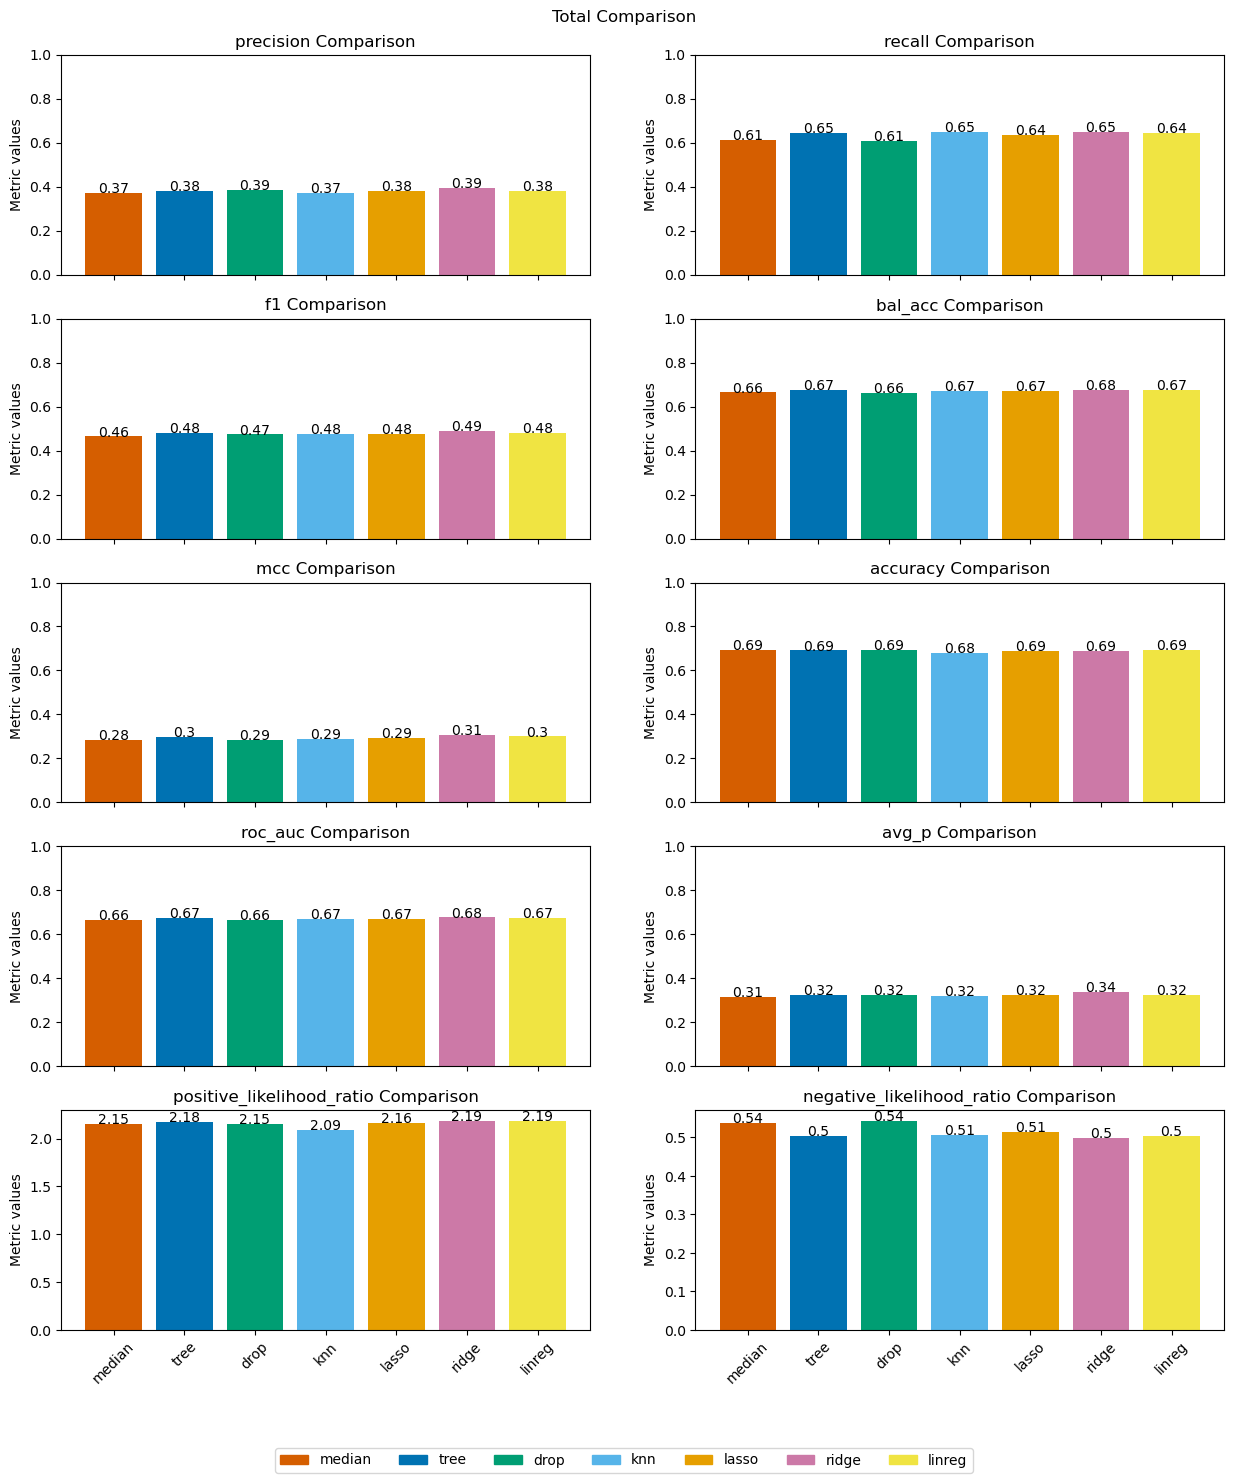

In [72]:
x = list(comp_df['name'])
fig, axs = plt.subplots(5, 2, figsize=(15, 15))
color_palette = [
    '#D55E00',  # Vermillion
    '#0072B2',  # Cerulean Blue
    '#009E73',  # Shamrock Green
    '#56B4E9',  # Sky Blue
    '#E69F00',  # Amber
    '#CC79A7',  # Pale Violet
    '#F0E442',  # Canary Yellow
    '#999999',   # Gray
    '#882255',
    '#1A1A1A',  # Onyx
]

legend_handles = [mpatches.Patch(color=color, label=label) 
                  for color, label in zip(color_palette, x)]

i, j = 0, 0
for k in comp_df.columns:
    if k != 'name':
        ax = axs[i, j]
        l = list(comp_df[k])
        ax.bar(x, height=l, color=color_palette)
        ax.set_ylabel("Metric values")
        if k not in ['positive_likelihood_ratio', 'negative_likelihood_ratio']:
            ax.set_ylim(top=1)
        if i == 4:
            ax.tick_params(axis='x', labelrotation=45)
        else:
            ax.set_xticklabels([])
        ax.set_title(f"{k} Comparison")

        for q in range(len(l)):
            ax.text(q, l[q], np.round(l[q], 2), ha='center')  # Aligning text at center

        j += 1
        if j == 2:
            i += 1
            j = 0

fig.legend(handles=legend_handles, 
           loc='lower center', 
           ncol=len(x), 
           bbox_to_anchor=(0.5, 0.0))
fig.subplots_adjust(top=0.95, bottom=0.1)
fig.suptitle("Total Comparison")
plt.savefig("images/total_comp.png")
plt.show()

In [65]:
pr_curves = {report:(reports[report]['pr_curve'], reports[report]['avg_p']) for report in reports}
roc_curves = {report:(reports[report]['roc_curve'], reports[report]['roc_auc']) for report in reports}

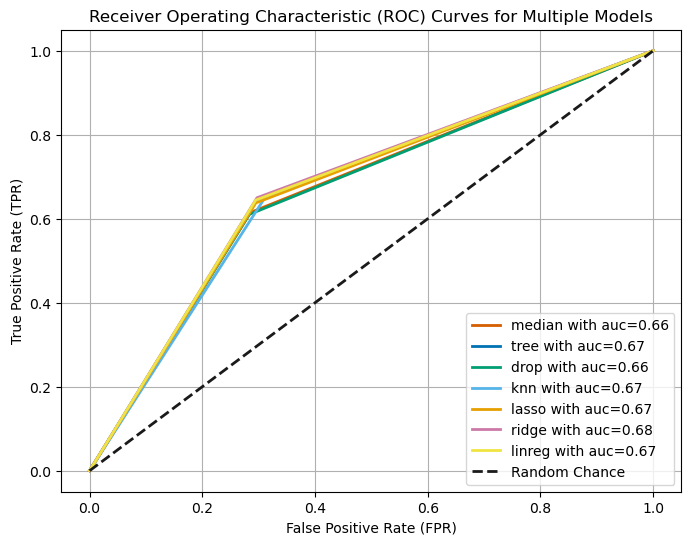

In [66]:
plt.figure(figsize=(8, 6))
color_palette = [
    '#D55E00',  # Vermillion
    '#0072B2',  # Cerulean Blue
    '#009E73',  # Shamrock Green
    '#56B4E9',  # Sky Blue
    '#E69F00',  # Amber
    '#CC79A7',  # Pale Violet
    '#F0E442',  # Canary Yellow
    '#999999',   # Gray
    '#882255',
    '#1A1A1A',  # Onyx
]
k = list(roc_curves.keys())
for i in range(len(k)):
    roc, roc_auc = roc_curves[k[i]]
    fpr, tpr, thresholds = roc
    plt.plot(fpr, tpr, color=color_palette[i], lw=2, label=f"{k[i]} with auc={roc_auc:.2f}") # Plot Model 1's ROC curve

# Plot the random chance line (diagonal line)
plt.plot([0, 1], [0, 1], color=color_palette[-1], lw=2, linestyle='--', label='Random Chance')

plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('Receiver Operating Characteristic (ROC) Curves for Multiple Models')
plt.legend(loc='lower right')
plt.grid(True)
plt.savefig("images/roc_curves.png")
plt.show()

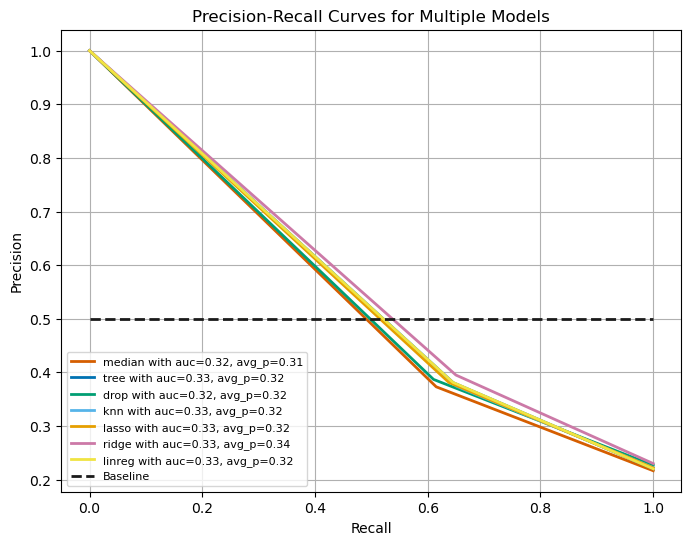

In [67]:
plt.figure(figsize=(8, 6))
color_palette = [
    '#D55E00',  # Vermillion
    '#0072B2',  # Cerulean Blue
    '#009E73',  # Shamrock Green
    '#56B4E9',  # Sky Blue
    '#E69F00',  # Amber
    '#CC79A7',  # Pale Violet
    '#F0E442',  # Canaryp,  Yellow
    '#999999',   # Gray
    '#882255',
    '#1A1A1A',  # Onyx
]
k = list(pr_curves.keys())
for i in range(len(k)):
    pr, avg_p = pr_curves[k[i]]
    p, r, thresholds = pr
    pr_auc = auc(p, r)
    plt.plot(r, p, color=color_palette[i], lw=2, label=f"{k[i]} with auc={pr_auc:.2f}, avg_p={avg_p:.2f}") # Plot Model 1's ROC curve

# Plot the random chance line (diagonal line)
plt.plot([0, 1], [0.5, 0.5], color=color_palette[-1], lw=2, linestyle='--', label='Baseline')

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curves for Multiple Models')
plt.legend(loc='lower left', fontsize=8)
plt.grid(True)
plt.savefig("images/pr_curves.png")
plt.show()

### Conclusion

<b>The trade-off between Listwise Deletion and Imputation:</b><br>
| Listwise Deletion | Imputation |
| :---------------- | :--------- |
| Involves deletion of rows with missing values | Involves adding placeholders in rows with missing values |
| Less computationally expensive | Better retains the relation between the features |
| Can remove significant datapoints required for the task | More computationally intensive |
| Use with a very small fraction (\< 1%) of the data has missing values | Can be used satisfactorily with large datasets|

<b>Linear vs Non-Linear Regression model performance comparison</b>:<br>
Linear regression models perform marginally better than the non-linear ones. However, due to a lack of significant difference in the metrics, we cannot say surely whether the data obeys a linear relationship or not.

<b>Implication of each method:</b>
1. Median : the missing values are not far off from the central tendency, which when not true induces significant bias
2. Linear Regression : the features (especially the BILL_AMT and PAY_AMT) obey a linear relationship among themselves
3. Ridge Linear Regression : focus on a few features affecting the incomplete feature by introducing a baised estimator
4. Lasso Linear Regression : focus on a few features affecting the incomplete feature by introducing a baised estimator
5. KNeighbors Regression : assumes a clustering or a smoothness relation (closer the data points are in terms of their features, the closer their value is for the incomplete feature)
6. DecisionTreeRegression : We can divide the features into continous sections each dictating the incomplete feature value (or assuming the incomplete feature follows a piece-wise function pattern)

<b>Best Strategy</b>: Perform a Linear Regression on the missing values from rest of the data. 